# THESIS FINAL: UNI + CLAM + RetNet with ALL IMPROVEMENTS

## Features
- All accuracy metrics (Binary, Grading, Per-Grade, Confusion Matrix)
- All fusion strategies (Add, Gated, Cross-Attention, Concat, Learnable Weight)
- Learnable Gamma
- Ordinal-Aware Loss
- Multi-Scale Retention
- Grade-Aware Attention
- Checkpoint Manager for resumable training

---

## Metrics Computed

| Metric | Description |
|--------|-------------|
| **QWK** | Quadratic Weighted Kappa (main) |
| **Binary Accuracy** | Cancer (1-5) vs No Cancer (0) |
| **Binary Precision/Recall/F1** | Cancer detection quality |
| **Grading Accuracy** | Overall 6-class accuracy |
| **Per-Grade Accuracy** | Accuracy for each grade (0-5) |
| **Per-Grade F1** | F1 score for each grade |
| **Macro F1** | Average F1 across all grades |
| **Confusion Matrix** | Full 6x6 matrix |

---

## Model Variants (16 total)

| Category | Variants |
|----------|----------|
| Baselines | B0_CLAM, B1_CLAM_RetNet_Original |
| Fusion | F1_Gated, F2_CrossAttn, F3_Concat, F4_LearnableWeight |
| Improvements | I1_LearnableGamma, I2_MultiScale, I3_OrdinalLoss, I4_GradeAttention |
| Combinations | C1, C2, C3, C4_FULL (Expected Best) |

## IMPORTS AND SETUP

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_score,
    recall_score,
    classification_report
)
from scipy import stats
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## CONFIGURATION

In [2]:
CONFIG = {
    # Paths
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/uni/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v11_thesis_complete/',

    # Model
    'feature_dim': 1024,  # UNI encoder
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 8,

    # Best HP from ablation
    'best_hp': {
        'dropout': 0.15,
        'attention_temperature': 0.7,
        'lr': 1e-4,
        'weight_decay': 1e-5,
    },

    # Training
    'epochs': 50,
    'early_stopping_patience': 10,

    # CV
    'n_folds': 5,
    'seed': 42,

    # Grade names
    'grade_names': ['Grade 0 (No Cancer)', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'],
}

import random
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

os.makedirs(CONFIG['results_dir'], exist_ok=True)
print(f'Results will be saved to: {CONFIG["results_dir"]}')

Device: cuda
Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v11_thesis_complete/


## CHECKPOINT MANAGER

Handles saving/loading progress for resumable training.

In [3]:
class CheckpointManager:
    """Manages checkpoints for resuming training after interruption."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'fold_progress.json')

    def _save_json(self, filepath, data):
        """Save JSON with retry."""
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2, default=str)
                return True
            except Exception as e:
                print(f'Save attempt {attempt+1} failed: {e}')
                time.sleep(1)
        return False

    def _load_json(self, filepath):
        """Load JSON safely."""
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    # ========== EXPERIMENT LEVEL ==========

    def get_completed_experiments(self):
        """Get dict of completed experiments."""
        return self._load_json(self.progress_file)

    def is_experiment_completed(self, experiment_name):
        """Check if experiment is completed."""
        return experiment_name in self.get_completed_experiments()

    def save_experiment_result(self, experiment_name, results):
        """Save completed experiment result."""
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)
        print(f'  [Checkpoint] Saved {experiment_name}')

    def load_experiment_result(self, experiment_name):
        """Load experiment result."""
        data = self.get_completed_experiments()
        if experiment_name in data:
            return data[experiment_name]['results']
        return None

    # ========== FOLD LEVEL ==========

    def get_fold_progress(self, experiment_name):
        """Get fold progress for an experiment."""
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        """Save a single fold result."""
        data = self._load_json(self.fold_progress_file)

        if experiment_name not in data:
            data[experiment_name] = {
                'completed_folds': [],
                'fold_results': [],
                'started_at': datetime.now().isoformat()
            }

        # Add fold result if not already present
        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({
                'fold': fold_idx,
                'metrics': fold_metrics,
                'completed_at': datetime.now().isoformat()
            })

        data[experiment_name]['last_updated'] = datetime.now().isoformat()
        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        """Clear fold progress after experiment completion."""
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)

    # ========== STATUS ==========

    def get_status(self):
        """Get overall checkpoint status."""
        experiments = self.get_completed_experiments()
        fold_data = self._load_json(self.fold_progress_file)

        return {
            'completed_experiments': len(experiments),
            'in_progress_experiments': len(fold_data),
            'experiment_names': list(experiments.keys()),
            'in_progress_names': list(fold_data.keys())
        }

# Initialize checkpoint manager
checkpoint_manager = CheckpointManager(CONFIG['results_dir'])

# Show status
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['completed_experiments'] > 0:
    print(f'  Completed: {status["experiment_names"]}')


[Checkpoint Status]
  Completed experiments: 0
  In-progress experiments: 0


## DETAILED METRICS COMPUTATION

In [4]:
def compute_all_metrics(y_true, y_pred):
    """
    Compute ALL metrics:
    1. QWK
    2. Binary (Cancer vs No Cancer)
    3. Grading (6-class)
    4. Per-Grade
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # =====================
    # 1. QWK (Main Metric)
    # =====================
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    # =====================
    # 2. BINARY METRICS (Cancer vs No Cancer)
    # =====================
    # Grade 0 = No Cancer (Negative)
    # Grade 1-5 = Cancer (Positive)
    y_true_binary = (y_true > 0).astype(int)
    y_pred_binary = (y_pred > 0).astype(int)

    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)
    binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)  # Sensitivity
    binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)

    # Specificity (True Negative Rate)
    tn = ((y_true_binary == 0) & (y_pred_binary == 0)).sum()
    fp = ((y_true_binary == 0) & (y_pred_binary == 1)).sum()
    binary_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # =====================
    # 3. GRADING METRICS (6-class)
    # =====================
    grading_accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # =====================
    # 4. PER-GRADE METRICS
    # =====================
    per_grade_accuracy = {}
    per_grade_precision = {}
    per_grade_recall = {}
    per_grade_f1 = {}
    per_grade_support = {}

    precision_per_class = precision_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)
    recall_per_class = recall_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)
    f1_per_class = f1_score(y_true, y_pred, labels=range(6), average=None, zero_division=0)

    for grade in range(6):
        mask = (y_true == grade)
        support = mask.sum()
        per_grade_support[grade] = int(support)

        if support > 0:
            per_grade_accuracy[grade] = float((y_pred[mask] == grade).mean())
        else:
            per_grade_accuracy[grade] = 0.0

        per_grade_precision[grade] = float(precision_per_class[grade])
        per_grade_recall[grade] = float(recall_per_class[grade])
        per_grade_f1[grade] = float(f1_per_class[grade])

    # =====================
    # 5. CONFUSION MATRIX
    # =====================
    cm = confusion_matrix(y_true, y_pred, labels=range(6))

    return {
        # Main
        'qwk': float(qwk),

        # Binary
        'binary_accuracy': float(binary_accuracy),
        'binary_precision': float(binary_precision),
        'binary_recall': float(binary_recall),  # Sensitivity
        'binary_specificity': float(binary_specificity),
        'binary_f1': float(binary_f1),

        # Grading
        'grading_accuracy': float(grading_accuracy),
        'macro_f1': float(macro_f1),
        'weighted_f1': float(weighted_f1),

        # Per-Grade
        'per_grade_accuracy': per_grade_accuracy,
        'per_grade_precision': per_grade_precision,
        'per_grade_recall': per_grade_recall,
        'per_grade_f1': per_grade_f1,
        'per_grade_support': per_grade_support,

        # Confusion Matrix
        'confusion_matrix': cm.tolist(),
    }


def print_metrics(metrics, name="Model"):
    """Pretty print all metrics."""
    print(f'\n{"="*70}')
    print(f'METRICS: {name}')
    print(f'{"="*70}')

    print(f'\n--- MAIN ---')
    print(f'  QWK: {metrics["qwk"]:.4f}')

    print(f'\n--- BINARY (Cancer vs No Cancer) ---')
    print(f'  Accuracy:    {metrics["binary_accuracy"]*100:.2f}%')
    print(f'  Precision:   {metrics["binary_precision"]:.4f}')
    print(f'  Recall/Sens: {metrics["binary_recall"]:.4f}')
    print(f'  Specificity: {metrics["binary_specificity"]:.4f}')
    print(f'  F1 Score:    {metrics["binary_f1"]:.4f}')

    print(f'\n--- GRADING (6-class) ---')
    print(f'  Accuracy:    {metrics["grading_accuracy"]*100:.2f}%')
    print(f'  Macro F1:    {metrics["macro_f1"]:.4f}')
    print(f'  Weighted F1: {metrics["weighted_f1"]:.4f}')

    # Handle both int and string keys
    def get_grade(d, g):
        return d.get(g, d.get(str(g), 0))

    print(f'\n--- PER-GRADE ---')
    print(f'{"Grade":<12} {"Support":>8} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} {"F1":>10}')
    print('-'*65)
    for g in range(6):
        print(f'Grade {g:<6} {get_grade(metrics["per_grade_support"], g):>8} '
              f'{get_grade(metrics["per_grade_accuracy"], g)*100:>9.1f}% '
              f'{get_grade(metrics["per_grade_precision"], g):>10.4f} '
              f'{get_grade(metrics["per_grade_recall"], g):>10.4f} '
              f'{get_grade(metrics["per_grade_f1"], g):>10.4f}')

## MODEL COMPONENTS

In [5]:
class GatedAttention(nn.Module):
    """CLAM's Gated Attention Mechanism"""
    def __init__(self, input_dim=512, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x, temperature=1.0):
        a = self.attention_a(x)
        b = self.attention_b(x)
        return self.attention_c(a * b).squeeze(-1) / temperature

## FUSION STRATEGIES

In [6]:
class LearnableWeightFusion(nn.Module):
    """Option A: Single learnable weight alpha"""
    def __init__(self, hidden_dim):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(0.5))

    def forward(self, M_clam, M_retention):
        alpha = torch.sigmoid(self.alpha)  # Constrain to (0, 1)
        return alpha * M_clam + (1 - alpha) * M_retention

    def get_weight(self):
        return torch.sigmoid(self.alpha).item()


class GatedFusion(nn.Module):
    """Option B: Gated fusion with learned gate"""
    def __init__(self, hidden_dim):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Sigmoid()
        )

    def forward(self, M_clam, M_retention):
        concat = torch.cat([M_clam, M_retention], dim=-1)
        g = self.gate(concat)
        return g * M_clam + (1 - g) * M_retention


class ConcatFusion(nn.Module):
    """Option C: Concatenate + Project"""
    def __init__(self, hidden_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

    def forward(self, M_clam, M_retention):
        return self.proj(torch.cat([M_clam, M_retention], dim=-1))


class CrossAttentionFusion(nn.Module):
    """Option D: Cross-attention (CLAM attends to Retention)"""
    def __init__(self, hidden_dim, num_heads=4):
        super().__init__()
        self.cross_attn = nn.MultiheadAttention(hidden_dim, num_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)
        self.ffn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Dropout(0.1)
        )

    def forward(self, M_clam, M_retention):
        # Add batch and sequence dimensions
        q = M_clam.unsqueeze(0).unsqueeze(0)      # (1, 1, D)
        kv = M_retention.unsqueeze(0).unsqueeze(0) # (1, 1, D)

        # Cross attention
        attn_out, _ = self.cross_attn(q, kv, kv)
        out = self.norm1(q + attn_out)
        out = self.norm2(out + self.ffn(out))

        return out.squeeze(0).squeeze(0)

## RETENTION HEADS (Learnable and Fixed Gamma)

In [7]:
class LearnableGammaRetentionHead(nn.Module):
    """Retention head with LEARNABLE gamma"""
    def __init__(self, hidden_dim, num_heads, init_gamma=0.9):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** -0.5

        # Learnable gamma
        self.gamma_logit = nn.Parameter(torch.tensor(np.log(init_gamma / (1 - init_gamma + 1e-8))))

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    @property
    def gamma(self):
        # Constrain to (0.5, 0.999)
        return 0.5 + 0.499 * torch.sigmoid(self.gamma_logit)

    def forward(self, x, coords=None):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        if coords is not None:
            # Spatial decay
            diff = coords.unsqueeze(0) - coords.unsqueeze(1)
            distances = torch.norm(diff.float(), dim=-1)
            normalized = distances / (distances.max() + 1e-6)
            D = self.gamma ** normalized
            scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale * D
        else:
            # No spatial decay
            scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale

        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V)


class FixedGammaRetentionHead(nn.Module):
    """Retention head with FIXED gamma (original)"""
    def __init__(self, hidden_dim, num_heads, gamma=0.9):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.gamma = gamma

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x, coords=None):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        if coords is not None:
            diff = coords.unsqueeze(0) - coords.unsqueeze(1)
            distances = torch.norm(diff.float(), dim=-1)
            normalized = distances / (distances.max() + 1e-6)
            D = self.gamma ** normalized
            scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale * D
        else:
            scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale

        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V)

## LOSS FUNCTIONS (Including Ordinal-Aware)

In [8]:
class FocalLoss(nn.Module):
    """Standard Focal Loss"""
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


class OrdinalCrossEntropyLoss(nn.Module):
    """CE + Ordinal penalty (penalize far predictions)"""
    def __init__(self, n_classes=6, lambda_ordinal=0.5):
        super().__init__()
        self.n_classes = n_classes
        self.lambda_ordinal = lambda_ordinal

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        # Standard CE
        ce_loss = F.cross_entropy(logits, target)

        # Ordinal penalty: (expected_grade - true_grade)^2
        probs = F.softmax(logits, dim=1)
        grades = torch.arange(self.n_classes, device=logits.device).float()
        expected_grade = torch.sum(probs * grades, dim=1)
        ordinal_loss = torch.mean((expected_grade - target.float()) ** 2)

        return ce_loss + self.lambda_ordinal * ordinal_loss


class FocalOrdinalLoss(nn.Module):
    """Focal Loss + Ordinal penalty"""
    def __init__(self, n_classes=6, focal_gamma=1.0, lambda_ordinal=0.3):
        super().__init__()
        self.n_classes = n_classes
        self.focal_gamma = focal_gamma
        self.lambda_ordinal = lambda_ordinal

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        # Focal loss
        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        focal_loss = ((1 - pt) ** self.focal_gamma * ce).mean()

        # Ordinal penalty
        probs = F.softmax(logits, dim=1)
        grades = torch.arange(self.n_classes, device=logits.device).float()
        expected_grade = torch.sum(probs * grades, dim=1)
        ordinal_loss = torch.mean((expected_grade - target.float()) ** 2)

        return focal_loss + self.lambda_ordinal * ordinal_loss


def get_loss_fn(loss_type):
    if loss_type == 'ce':
        return nn.CrossEntropyLoss()
    elif loss_type == 'focal':
        return FocalLoss(gamma=1.0)
    elif loss_type == 'ordinal':
        return OrdinalCrossEntropyLoss(n_classes=6, lambda_ordinal=0.5)
    elif loss_type == 'focal_ordinal':
        return FocalOrdinalLoss(n_classes=6, focal_gamma=1.0, lambda_ordinal=0.3)
    else:
        return nn.CrossEntropyLoss()

## MULTI-SCALE RETENTION

In [9]:
class MultiScaleRetention(nn.Module):
    """Retention at multiple spatial scales (K values)"""
    def __init__(self, hidden_dim, num_heads, K_values=[64, 128, 256],
                 use_spatial=False, use_learnable_gamma=False):
        super().__init__()
        self.K_values = K_values
        self.use_spatial = use_spatial

        # One retention module per scale
        self.retentions = nn.ModuleList()
        for _ in K_values:
            heads = nn.ModuleList()
            init_gammas = np.linspace(0.7, 0.99, num_heads)
            for i in range(num_heads):
                if use_learnable_gamma:
                    heads.append(LearnableGammaRetentionHead(hidden_dim, num_heads, init_gammas[i]))
                else:
                    heads.append(FixedGammaRetentionHead(hidden_dim, num_heads, init_gammas[i]))
            self.retentions.append(heads)

        self.output_projs = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim) for _ in K_values
        ])

        # Fusion across scales
        if len(K_values) > 1:
            self.scale_fusion = nn.Sequential(
                nn.Linear(hidden_dim * len(K_values), hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.ReLU()
            )
        else:
            self.scale_fusion = None

    def forward(self, h, coords, attention_scores):
        scale_outputs = []

        for scale_idx, (K, heads, proj) in enumerate(zip(self.K_values, self.retentions, self.output_projs)):
            K_actual = min(K, h.size(0))
            topk_indices = torch.topk(attention_scores, K_actual).indices

            h_topk = h[topk_indices]
            coords_topk = coords[topk_indices] if self.use_spatial else None

            # Multi-head retention
            head_outputs = [head(h_topk, coords_topk) for head in heads]
            out = proj(torch.cat(head_outputs, dim=-1))
            out = torch.mean(out, dim=0)  # Aggregate

            scale_outputs.append(out)

        if self.scale_fusion is not None:
            return self.scale_fusion(torch.cat(scale_outputs, dim=-1))
        else:
            return scale_outputs[0]

    def get_learned_gammas(self):
        """Return learned gamma values"""
        gammas = []
        for scale_heads in self.retentions:
            scale_gammas = []
            for head in scale_heads:
                if hasattr(head, 'gamma') and isinstance(head.gamma, torch.Tensor):
                    scale_gammas.append(head.gamma.item())
                else:
                    scale_gammas.append(head.gamma)
            gammas.append(scale_gammas)
        return gammas

## GRADE-AWARE ATTENTION

In [10]:
class GradeAwareAttention(nn.Module):
    """
    Learnable grade queries that attend to patches.
    Helps model learn grade-specific patterns.
    """
    def __init__(self, hidden_dim, n_grades=6, num_heads=4):
        super().__init__()
        self.n_grades = n_grades

        # Learnable query for each grade
        self.grade_queries = nn.Parameter(torch.randn(n_grades, hidden_dim) * 0.02)

        self.attention = nn.MultiheadAttention(hidden_dim, num_heads, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim)

        # Project to final features
        self.proj = nn.Sequential(
            nn.Linear(hidden_dim * n_grades, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

    def forward(self, h, logits=None):
        # Reshape for attention
        queries = self.grade_queries.unsqueeze(0)  # (1, 6, D)
        keys_values = h.unsqueeze(0)                # (1, N, D)

        # Each grade query attends to all patches
        grade_features, attn_weights = self.attention(queries, keys_values, keys_values)
        grade_features = self.norm(grade_features)  # (1, 6, D)

        # Flatten and project
        grade_context = self.proj(grade_features.view(-1))  # (D,)

        return grade_context, attn_weights.squeeze(0)  # (D,), (6, N)

## RetNet ENHANCEMENT COMPONENTS

In [11]:
class SwishGate(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class FFNBlock(nn.Module):
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        hidden = dim * expansion
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


class RetNetEnhancement(nn.Module):
    """RetNet enhancement block (Norm + Residual + Gate + FFN)"""
    def __init__(self, hidden_dim, config):
        super().__init__()

        self.use_norm = config.get('use_norm', True)
        self.use_residual = config.get('use_residual', True)
        self.use_gate = config.get('use_gate', True)
        self.use_ffn = config.get('use_ffn', True)

        if self.use_norm:
            norm_type = config.get('norm_type', 'group')
            if norm_type == 'layer':
                self.norm = nn.LayerNorm(hidden_dim)
            else:
                self.norm = nn.GroupNorm(config.get('num_groups', 8), hidden_dim)

        if self.use_gate:
            self.gate = SwishGate(hidden_dim)

        if self.use_ffn:
            self.ffn = FFNBlock(hidden_dim, config.get('ffn_expansion', 4))

        self.dropout = nn.Dropout(0.1)

    def forward(self, x, identity=None):
        out = self.dropout(x)

        if self.use_norm:
            out = self.norm(out)
        if self.use_residual and identity is not None:
            out = out + identity
        if self.use_gate:
            out = self.gate(out)
        if self.use_ffn:
            out = self.ffn(out)

        return out

## MAIN MODEL: UNIFIED CLAM + RetNet

In [12]:
class CLAMRetNetComplete(nn.Module):
    """
    Complete CLAM + RetNet model with ALL improvements:
    1. Configurable fusion (add, gated, cross_attn, concat, learnable_weight)
    2. Learnable or fixed gamma
    3. Multi-scale K values
    4. Grade-aware attention
    5. RetNet enhancements (norm, residual, gate, FFN)
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=8, config=None):
        super().__init__()

        if config is None:
            config = {}

        self.model_type = config.get('model_type', 'CLAM_RetNet')
        self.fusion_type = config.get('fusion_type', 'add')
        self.use_grade_attention = config.get('use_grade_attention', False)
        self.use_spatial = config.get('use_spatial', False)
        dropout = CONFIG['best_hp']['dropout']

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM attention
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)

        # Retention module (if not pure CLAM)
        if self.model_type != 'CLAM':
            self.retention = MultiScaleRetention(
                hidden_dim=hidden_dim,
                num_heads=num_heads,
                K_values=config.get('K_values', [128]),
                use_spatial=self.use_spatial,
                use_learnable_gamma=config.get('use_learnable_gamma', False)
            )

            # RetNet enhancement
            if config.get('use_retnet_enhancement', True):
                self.retnet_enhance = RetNetEnhancement(hidden_dim, config)
            else:
                self.retnet_enhance = None
        else:
            self.retention = None
            self.retnet_enhance = None

        # Fusion module
        if self.model_type != 'CLAM':
            if self.fusion_type == 'gated':
                self.fusion = GatedFusion(hidden_dim)
            elif self.fusion_type == 'cross_attention':
                self.fusion = CrossAttentionFusion(hidden_dim)
            elif self.fusion_type == 'concat':
                self.fusion = ConcatFusion(hidden_dim)
            elif self.fusion_type == 'learnable_weight':
                self.fusion = LearnableWeightFusion(hidden_dim)
            else:  # 'add'
                self.fusion = None
        else:
            self.fusion = None

        # Grade-aware attention
        if self.use_grade_attention:
            self.grade_attention = GradeAwareAttention(hidden_dim, n_classes)
            classifier_input = hidden_dim * 2
        else:
            self.grade_attention = None
            classifier_input = hidden_dim

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(classifier_input, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, x, coords, temperature=0.7):
        # Feature transform
        h = self.feature_transform(x)

        # CLAM attention
        A = self.attention(h, temperature)
        A_softmax = F.softmax(A, dim=0)

        # Top-K for CLAM
        K = min(128, h.size(0))
        topk_indices = torch.topk(A, K).indices
        h_topk = h[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # Retention (if enabled)
        if self.retention is not None:
            M_retention = self.retention(h, coords, A)

            # RetNet enhancement
            if self.retnet_enhance is not None:
                M_retention = self.retnet_enhance(M_retention, M_retention)

            # Fusion
            if self.fusion is not None:
                M = self.fusion(M_clam, M_retention)
            else:
                M = M_clam + M_retention
        else:
            M = M_clam

        # Grade-aware attention
        if self.grade_attention is not None:
            grade_context, _ = self.grade_attention(h_topk)
            M = torch.cat([M, grade_context], dim=-1)

        return self.classifier(M)

    def get_learned_gammas(self):
        if self.retention is not None:
            return self.retention.get_learned_gammas()
        return None

    def get_fusion_weight(self):
        if hasattr(self.fusion, 'get_weight'):
            return self.fusion.get_weight()
        return None

## MODEL VARIANTS

In [13]:
MODEL_VARIANTS = {
    # =========================================================================
    # BASELINES
    # =========================================================================

    'B0_CLAM': {
        'model_type': 'CLAM',
        'description': 'CLAM Baseline',
        'fusion_type': 'none',
        'loss_type': 'focal',
    },

    'B1_CLAM_RetNet_Original': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet (Original - 0.8761)',
        'fusion_type': 'add',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    # =========================================================================
    # FUSION IMPROVEMENTS
    # =========================================================================

    'F1_GatedFusion': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Gated Fusion',
        'fusion_type': 'gated',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'F2_CrossAttnFusion': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Cross-Attention Fusion',
        'fusion_type': 'cross_attention',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'F3_ConcatFusion': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Concat Fusion',
        'fusion_type': 'concat',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'F4_LearnableWeightFusion': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Learnable Weight Fusion',
        'fusion_type': 'learnable_weight',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    # =========================================================================
    # OTHER IMPROVEMENTS
    # =========================================================================

    'I1_LearnableGamma': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Learnable Gamma',
        'fusion_type': 'add',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': True,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'I2_MultiScale': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Multi-Scale K',
        'fusion_type': 'add',
        'K_values': [64, 128, 256],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'I3_OrdinalLoss': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Ordinal Loss',
        'fusion_type': 'add',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal_ordinal',
    },

    'I4_GradeAttention': {
        'model_type': 'CLAM_RetNet',
        'description': 'CLAM + RetNet + Grade-Aware Attention',
        'fusion_type': 'add',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_grade_attention': True,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    # =========================================================================
    # COMBINATIONS (Best expected)
    # =========================================================================

    'C1_Gated_MultiScale': {
        'model_type': 'CLAM_RetNet',
        'description': 'Gated Fusion + Multi-Scale',
        'fusion_type': 'gated',
        'K_values': [64, 128, 256],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal',
    },

    'C2_Gated_Ordinal': {
        'model_type': 'CLAM_RetNet',
        'description': 'Gated Fusion + Ordinal Loss',
        'fusion_type': 'gated',
        'K_values': [128],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal_ordinal',
    },

    'C3_Gated_MultiScale_Ordinal': {
        'model_type': 'CLAM_RetNet',
        'description': 'Gated + Multi-Scale + Ordinal',
        'fusion_type': 'gated',
        'K_values': [64, 128, 256],
        'use_spatial': False,
        'use_learnable_gamma': False,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal_ordinal',
    },

    'C4_FULL_ALL_IMPROVEMENTS': {
        'model_type': 'CLAM_RetNet',
        'description': 'ALL IMPROVEMENTS COMBINED (EXPECTED BEST)',
        'fusion_type': 'gated',
        'K_values': [64, 128, 256],
        'use_spatial': False,
        'use_learnable_gamma': True,
        'use_grade_attention': True,
        'use_retnet_enhancement': True,
        'use_norm': True,
        'norm_type': 'group',
        'num_groups': 8,
        'use_residual': True,
        'use_gate': True,
        'use_ffn': True,
        'loss_type': 'focal_ordinal',
    },
}

print(f'\nTotal variants: {len(MODEL_VARIANTS)}')
for key, cfg in MODEL_VARIANTS.items():
    print(f'  {key}: {cfg["description"]}')


Total variants: 14
  B0_CLAM: CLAM Baseline
  B1_CLAM_RetNet_Original: CLAM + RetNet (Original - 0.8761)
  F1_GatedFusion: CLAM + RetNet + Gated Fusion
  F2_CrossAttnFusion: CLAM + RetNet + Cross-Attention Fusion
  F3_ConcatFusion: CLAM + RetNet + Concat Fusion
  F4_LearnableWeightFusion: CLAM + RetNet + Learnable Weight Fusion
  I1_LearnableGamma: CLAM + RetNet + Learnable Gamma
  I2_MultiScale: CLAM + RetNet + Multi-Scale K
  I3_OrdinalLoss: CLAM + RetNet + Ordinal Loss
  I4_GradeAttention: CLAM + RetNet + Grade-Aware Attention
  C1_Gated_MultiScale: Gated Fusion + Multi-Scale
  C2_Gated_Ordinal: Gated Fusion + Ordinal Loss
  C3_Gated_MultiScale_Ordinal: Gated + Multi-Scale + Ordinal
  C4_FULL_ALL_IMPROVEMENTS: ALL IMPROVEMENTS COMBINED (EXPECTED BEST)


## DATASET

In [14]:
class PANDADataset(Dataset):
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]

def collate_fn(batch):
    return batch[0]

## TRAINING FUNCTION

In [15]:
class EarlyStopping:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


def train_fold(config, train_loader, val_loader, device):
    """Train one fold and return all metrics."""

    model = CLAMRetNetComplete(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=CONFIG['n_classes'],
        num_heads=CONFIG['num_heads'],
        config=config
    ).to(device)

    params = sum(p.numel() for p in model.parameters())

    criterion = get_loss_fn(config.get('loss_type', 'focal'))
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CONFIG['best_hp']['lr'],
        weight_decay=CONFIG['best_hp']['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    best_qwk = -1
    best_state = None
    best_epoch = 0

    for epoch in range(CONFIG['epochs']):
        model.train()
        for feat, coord, label, _ in train_loader:
            feat, coord = feat.to(device), coord.to(device)
            label = torch.tensor(label).to(device)

            optimizer.zero_grad()
            out = model(feat, coord)
            loss = criterion(out, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        scheduler.step()

        # Validate
        model.eval()
        preds, labels = [], []
        with torch.no_grad():
            for feat, coord, label, _ in val_loader:
                feat, coord = feat.to(device), coord.to(device)
                out = model(feat, coord)
                preds.append(out.argmax().cpu().item())
                labels.append(label)

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stop(qwk):
            break

    # Final evaluation with best model
    model.load_state_dict(best_state)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for feat, coord, label, _ in val_loader:
            feat, coord = feat.to(device), coord.to(device)
            out = model(feat, coord)
            all_preds.append(out.argmax().cpu().item())
            all_labels.append(label)

    # Compute all metrics
    metrics = compute_all_metrics(all_labels, all_preds)
    metrics['best_epoch'] = best_epoch
    metrics['params'] = params

    # Get learned values if available
    metrics['learned_gammas'] = model.get_learned_gammas()
    metrics['fusion_weight'] = model.get_fusion_weight()

    return metrics

## 5-FOLD CV WITH CHECKPOINT SUPPORT

In [18]:
class SwishGate(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class FFNBlock(nn.Module):
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        hidden = dim * expansion
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


class RetNetEnhancement(nn.Module):
    """RetNet enhancement block (Norm + Residual + Gate + FFN) - FIXED for GroupNorm"""
    def __init__(self, hidden_dim, config):
        super().__init__()

        self.use_norm = config.get('use_norm', True)
        self.use_residual = config.get('use_residual', True)
        self.use_gate = config.get('use_gate', True)
        self.use_ffn = config.get('use_ffn', True)

        if self.use_norm:
            norm_type = config.get('norm_type', 'group')
            if norm_type == 'layer':
                self.norm = nn.LayerNorm(hidden_dim)
                self.norm_type = 'layer'
            else:
                self.norm = nn.GroupNorm(config.get('num_groups', 8), hidden_dim)
                self.norm_type = 'group'
        else:
            self.norm_type = None

        if self.use_gate:
            self.gate = SwishGate(hidden_dim)

        if self.use_ffn:
            self.ffn = FFNBlock(hidden_dim, config.get('ffn_expansion', 4))

        self.dropout = nn.Dropout(0.1)

    def forward(self, x, identity=None):
        out = self.dropout(x)

        if self.use_norm:
            if self.norm_type == 'group':
                # FIX: GroupNorm needs (N, C, *) - add dimensions if needed
                if out.dim() == 1:
                    out = self.norm(out.unsqueeze(0).unsqueeze(-1)).squeeze(-1).squeeze(0)
                elif out.dim() == 2:
                    out = self.norm(out.unsqueeze(-1)).squeeze(-1)
                else:
                    out = self.norm(out)
            else:
                # LayerNorm works with any shape
                out = self.norm(out)

        if self.use_residual and identity is not None:
            out = out + identity
        if self.use_gate:
            out = self.gate(out)
        if self.use_ffn:
            out = self.ffn(out)

        return out

## MAIN EXECUTION

In [19]:
print('='*70)
print('THESIS FINAL: UNI + CLAM + RetNet')
print('WITH ALL IMPROVEMENTS AND ALL METRICS')
print('='*70)

# Show checkpoint status
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['completed_experiments'] > 0:
    print(f'  Completed: {status["experiment_names"]}')
if status['in_progress_experiments'] > 0:
    print(f'  In-progress: {status["in_progress_names"]}')
print('='*70)

all_results = {}
skipped_count = 0

for variant_name, config in MODEL_VARIANTS.items():
    # Check if experiment is already completed
    if checkpoint_manager.is_experiment_completed(variant_name):
        print(f'\n[SKIP] {variant_name} - already completed')
        saved_result = checkpoint_manager.load_experiment_result(variant_name)
        if saved_result:
            all_results[variant_name] = saved_result
        skipped_count += 1
        continue

    results = run_5fold_cv(variant_name, config)

    if results:
        all_results[variant_name] = results
        # Save experiment result via checkpoint manager
        checkpoint_manager.save_experiment_result(variant_name, results)

    # Save intermediate results
    with open(os.path.join(CONFIG['results_dir'], 'all_results.json'), 'w') as f:
        json.dump(all_results, f, indent=2, default=str)

print(f'\n{"="*70}')
print(f'COMPLETED: {len(MODEL_VARIANTS) - skipped_count} experiments run, {skipped_count} skipped (loaded from checkpoint)')
print(f'{"="*70}')

THESIS FINAL: UNI + CLAM + RetNet
WITH ALL IMPROVEMENTS AND ALL METRICS

[Checkpoint Status]
  Completed experiments: 1
  In-progress experiments: 0
  Completed: ['B0_CLAM']

[SKIP] B0_CLAM - already completed

5-FOLD CV: B1_CLAM_RetNet_Original
Description: CLAM + RetNet (Original - 0.8761)
Samples: 600
  Fold 1/5... QWK=0.8718, GradeAcc=64.2%, BinaryAcc=96.7%
    [Checkpoint] Fold 1 saved
  Fold 2/5... QWK=0.9081, GradeAcc=67.5%, BinaryAcc=99.2%
    [Checkpoint] Fold 2 saved
  Fold 3/5... QWK=0.8492, GradeAcc=64.2%, BinaryAcc=92.5%
    [Checkpoint] Fold 3 saved
  Fold 4/5... QWK=0.8606, GradeAcc=47.5%, BinaryAcc=95.0%
    [Checkpoint] Fold 4 saved
  Fold 5/5... QWK=0.8907, GradeAcc=65.8%, BinaryAcc=95.8%
    [Checkpoint] Fold 5 saved

  SUMMARY:
    QWK:              0.8761 +/- 0.0211
    Grading Accuracy: 61.83% +/- 7.27%
    Binary Accuracy:  95.83% +/- 2.17%
  [Checkpoint] Saved B1_CLAM_RetNet_Original

5-FOLD CV: F1_GatedFusion
Description: CLAM + RetNet + Gated Fusion
Samples: 6

## RESULTS TABLES

In [20]:
# Helper to get values from nested dict with int/string key handling
def get_val(d, key, default=0):
    if isinstance(d, dict):
        return d.get(key, d.get(str(key), default))
    return default

print('\n' + '='*140)
print('MAIN METRICS COMPARISON')
print('='*140)
print(f'{"Variant":<35} {"QWK":<18} {"Grade Acc":<15} {"Binary Acc":<15} {"Macro F1":<15} {"Params":>12}')
print('-'*130)

sorted_results = sorted(all_results.items(), key=lambda x: x[1]['qwk']['mean'], reverse=True)

for name, r in sorted_results:
    qwk = f"{r['qwk']['mean']:.4f}+/-{r['qwk']['std']:.3f}"
    grade = f"{r['grading_accuracy']['mean']*100:.1f}%+/-{r['grading_accuracy']['std']*100:.1f}%"
    binary = f"{r['binary_accuracy']['mean']*100:.1f}%+/-{r['binary_accuracy']['std']*100:.1f}%"
    f1 = f"{r['macro_f1']['mean']:.4f}+/-{r['macro_f1']['std']:.3f}"
    print(f'{name:<35} {qwk:<18} {grade:<15} {binary:<15} {f1:<15} {r["params"]:>12,}')


MAIN METRICS COMPARISON
Variant                             QWK                Grade Acc       Binary Acc      Macro F1              Params
----------------------------------------------------------------------------------------------------------------------------------
F3_ConcatFusion                     0.8832+/-0.029     64.0%+/-3.1%    96.5%+/-2.3%    0.6285+/-0.034     4,860,935
F1_GatedFusion                      0.8785+/-0.023     61.0%+/-3.6%    94.7%+/-1.1%    0.6016+/-0.045     5,122,567
F4_LearnableWeightFusion            0.8776+/-0.025     60.7%+/-3.6%    95.5%+/-3.0%    0.5910+/-0.046     4,335,112
F2_CrossAttnFusion                  0.8771+/-0.023     61.8%+/-3.7%    96.2%+/-2.7%    0.6076+/-0.043     6,437,895
C2_Gated_Ordinal                    0.8766+/-0.022     62.3%+/-3.4%    96.3%+/-2.2%    0.6154+/-0.039     5,122,567
B1_CLAM_RetNet_Original             0.8761+/-0.021     61.8%+/-7.3%    95.8%+/-2.2%    0.6004+/-0.090     4,335,111
C3_Gated_MultiScale_Ordinal     

In [21]:
print('\n' + '='*120)
print('BINARY CLASSIFICATION (Cancer vs No Cancer)')
print('='*120)
print(f'{"Variant":<35} {"Accuracy":<12} {"Precision":<12} {"Recall":<12} {"Specificity":<12} {"F1":<12}')
print('-'*95)

for name, r in sorted(all_results.items(), key=lambda x: x[1]['binary_accuracy']['mean'], reverse=True):
    acc = f"{r['binary_accuracy']['mean']*100:.1f}%"
    prec = f"{r['binary_precision']['mean']:.4f}"
    rec = f"{r['binary_recall']['mean']:.4f}"
    spec = f"{r['binary_specificity']['mean']:.4f}"
    f1 = f"{r['binary_f1']['mean']:.4f}"
    print(f'{name:<35} {acc:<12} {prec:<12} {rec:<12} {spec:<12} {f1:<12}')


BINARY CLASSIFICATION (Cancer vs No Cancer)
Variant                             Accuracy     Precision    Recall       Specificity  F1          
-----------------------------------------------------------------------------------------------
F3_ConcatFusion                     96.5%        0.9858       0.9720       0.9300       0.9788      
I3_OrdinalLoss                      96.5%        0.9858       0.9720       0.9300       0.9788      
C2_Gated_Ordinal                    96.3%        0.9878       0.9680       0.9400       0.9776      
C3_Gated_MultiScale_Ordinal         96.3%        0.9858       0.9700       0.9300       0.9778      
F2_CrossAttnFusion                  96.2%        0.9838       0.9700       0.9200       0.9767      
I4_GradeAttention                   96.0%        0.9799       0.9720       0.9000       0.9759      
C1_Gated_MultiScale                 96.0%        0.9857       0.9660       0.9300       0.9756      
B1_CLAM_RetNet_Original             95.8%        0.

In [22]:
print('\n' + '='*120)
print('PER-GRADE ACCURACY')
print('='*120)
print(f'{"Variant":<35} {"G0":>10} {"G1":>10} {"G2":>10} {"G3":>10} {"G4":>10} {"G5":>10}')
print('-'*100)

for name, r in sorted_results[:10]:  # Top 10
    grades = []
    for g in range(6):
        grade_data = get_val(r['per_grade_accuracy'], g, {'mean': 0})
        if isinstance(grade_data, dict):
            acc = grade_data.get('mean', 0) * 100
        else:
            acc = grade_data * 100
        grades.append(f"{acc:.1f}%")
    print(f'{name:<35} {grades[0]:>10} {grades[1]:>10} {grades[2]:>10} {grades[3]:>10} {grades[4]:>10} {grades[5]:>10}')


PER-GRADE ACCURACY
Variant                                     G0         G1         G2         G3         G4         G5
----------------------------------------------------------------------------------------------------
F3_ConcatFusion                          93.0%      74.0%      40.0%      55.0%      48.0%      74.0%
F1_GatedFusion                           87.0%      52.0%      50.0%      47.0%      64.0%      66.0%
F4_LearnableWeightFusion                 93.0%      65.0%      35.0%      38.0%      58.0%      75.0%
F2_CrossAttnFusion                       92.0%      59.0%      48.0%      44.0%      60.0%      68.0%
C2_Gated_Ordinal                         94.0%      56.0%      46.0%      56.0%      49.0%      73.0%
B1_CLAM_RetNet_Original                  93.0%      65.0%      45.0%      39.0%      66.0%      63.0%
C3_Gated_MultiScale_Ordinal              93.0%      65.0%      44.0%      35.0%      67.0%      65.0%
I3_OrdinalLoss                           93.0%      51.0%      

## STATISTICAL SIGNIFICANCE

In [23]:
print('\n' + '='*80)
print('IMPROVEMENT ANALYSIS (vs Original CLAM + RetNet)')
print('='*80)

baseline = all_results.get('B1_CLAM_RetNet_Original', {})
baseline_qwk = baseline.get('qwk', {}).get('mean', 0)
baseline_qwks = baseline.get('qwk', {}).get('values', [0]*5)

print(f'\nBaseline (B1_CLAM_RetNet_Original): {baseline_qwk:.4f}')
print(f'\n{"Variant":<35} {"Delta QWK":>10} {"t-stat":>10} {"p-value":>10} {"Sig?":>8}')
print('-'*80)

for name, r in sorted_results:
    if name == 'B1_CLAM_RetNet_Original' or name == 'B0_CLAM':
        continue

    delta = r['qwk']['mean'] - baseline_qwk
    t_stat, p_val = stats.ttest_rel(r['qwk']['values'], baseline_qwks)
    sig = "Yes" if p_val < 0.05 else ""

    print(f'{name:<35} {delta:>+10.4f} {t_stat:>10.4f} {p_val:>10.4f} {sig:>8}')


IMPROVEMENT ANALYSIS (vs Original CLAM + RetNet)

Baseline (B1_CLAM_RetNet_Original): 0.8761

Variant                              Delta QWK     t-stat    p-value     Sig?
--------------------------------------------------------------------------------
F3_ConcatFusion                        +0.0072     0.6666     0.5415         
F1_GatedFusion                         +0.0024     0.3168     0.7673         
F4_LearnableWeightFusion               +0.0015     0.1436     0.8927         
F2_CrossAttnFusion                     +0.0010     0.1029     0.9230         
C2_Gated_Ordinal                       +0.0005     0.0502     0.9624         
C3_Gated_MultiScale_Ordinal            -0.0024    -0.2241     0.8337         
I3_OrdinalLoss                         -0.0035    -0.2755     0.7965         
C1_Gated_MultiScale                    -0.0040    -0.2950     0.7827         
C4_FULL_ALL_IMPROVEMENTS               -0.0041    -0.3832     0.7210         
I2_MultiScale                          -0.00

## VISUALIZATIONS

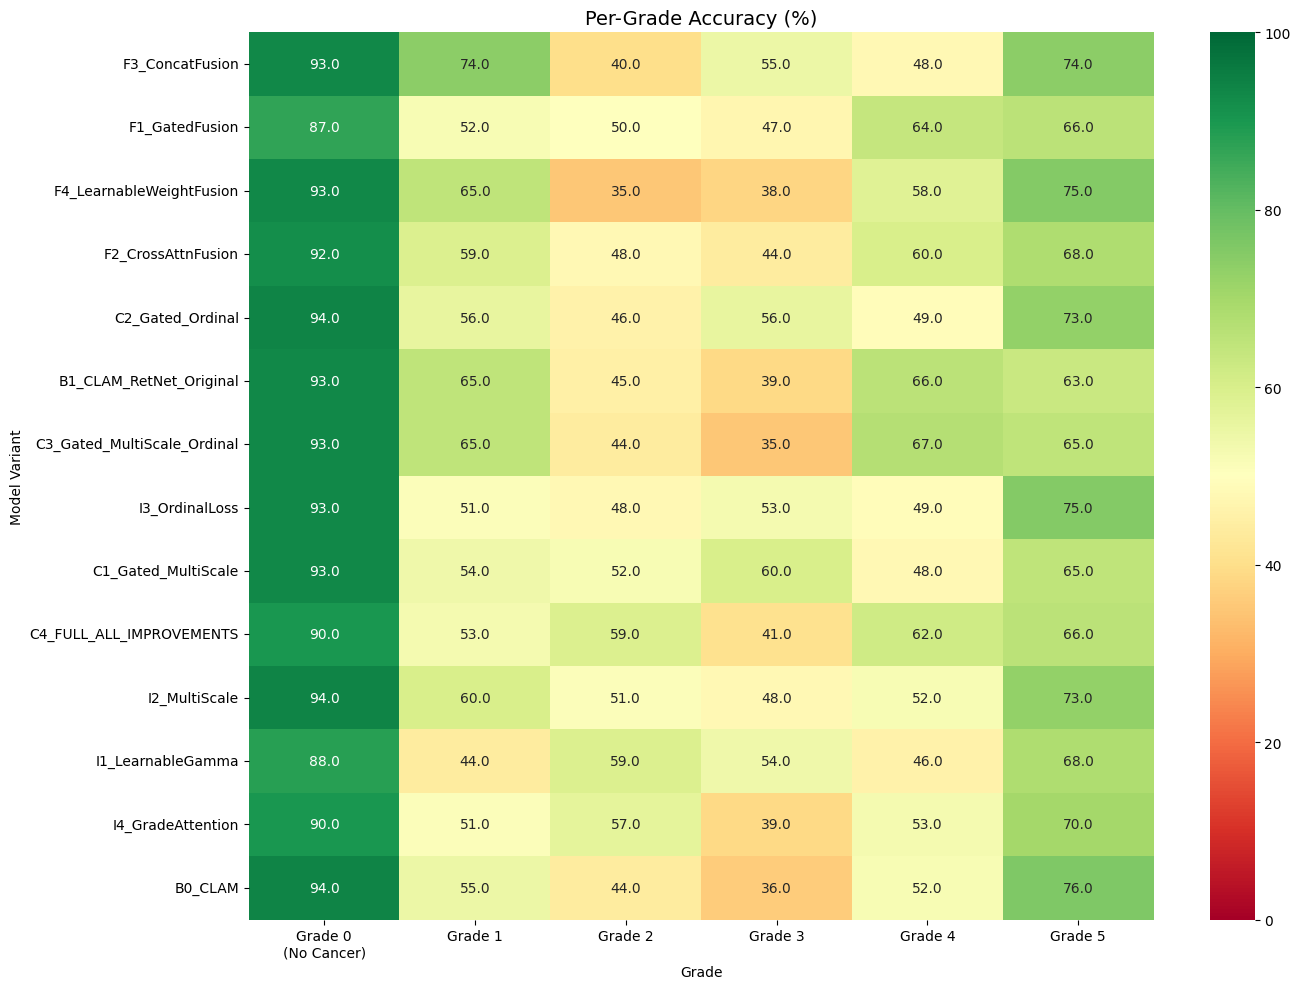

In [24]:
# 1. Per-Grade Accuracy Heatmap
fig, ax = plt.subplots(figsize=(14, 10))

models = []
data = []
for name, r in sorted_results:
    models.append(name)
    row = []
    for g in range(6):
        grade_data = get_val(r['per_grade_accuracy'], g, {'mean': 0})
        if isinstance(grade_data, dict):
            row.append(grade_data.get('mean', 0) * 100)
        else:
            row.append(grade_data * 100)
    data.append(row)

data = np.array(data)

sns.heatmap(data, annot=True, fmt='.1f', cmap='RdYlGn',
            xticklabels=['Grade 0\n(No Cancer)', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'],
            yticklabels=models, ax=ax, vmin=0, vmax=100)
ax.set_title('Per-Grade Accuracy (%)', fontsize=14)
ax.set_xlabel('Grade')
ax.set_ylabel('Model Variant')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'per_grade_accuracy_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

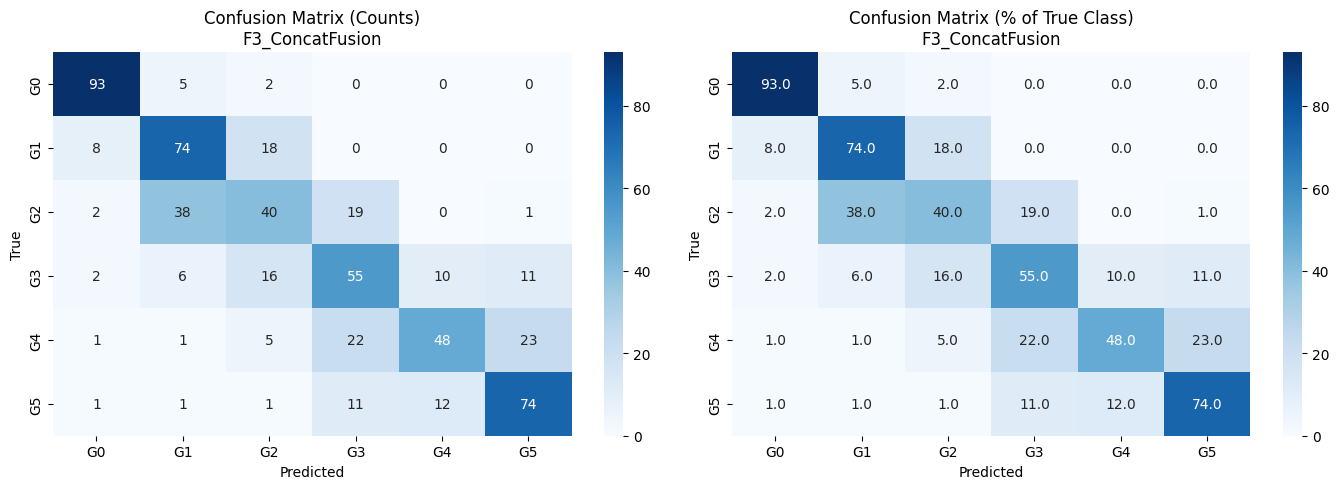

In [25]:
# 2. Confusion Matrix for Best Model
best_name, best_result = sorted_results[0]
cm = np.array(best_result['total_confusion_matrix'])
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
            yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'])
axes[0].set_title(f'Confusion Matrix (Counts)\n{best_name}')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
            yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'])
axes[1].set_title(f'Confusion Matrix (% of True Class)\n{best_name}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'confusion_matrix_best.png'), dpi=300, bbox_inches='tight')
plt.show()

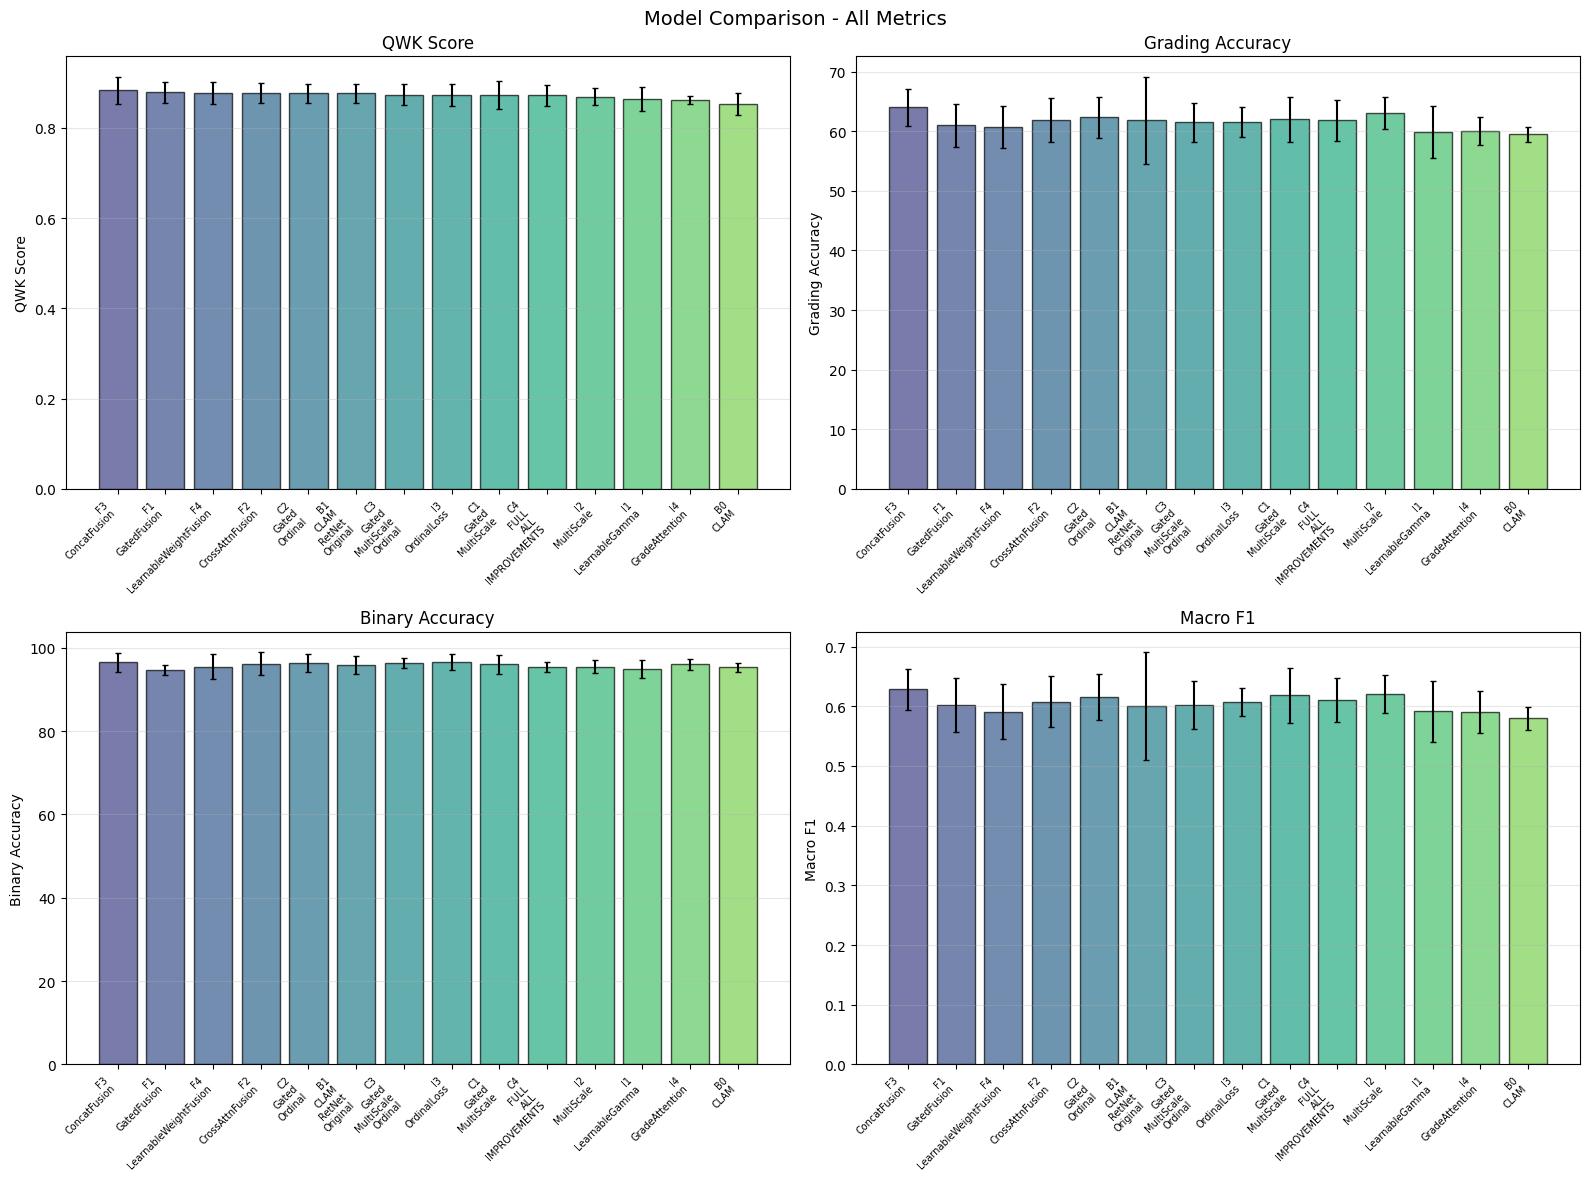

In [26]:
# 3. Metrics Comparison Bar Chart
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics_to_plot = [
    ('qwk', 'QWK Score', axes[0, 0]),
    ('grading_accuracy', 'Grading Accuracy', axes[0, 1]),
    ('binary_accuracy', 'Binary Accuracy', axes[1, 0]),
    ('macro_f1', 'Macro F1', axes[1, 1]),
]

for metric_key, metric_name, ax in metrics_to_plot:
    names = []
    means = []
    stds = []

    for name, r in sorted_results:
        names.append(name.replace('_', '\n'))
        mean = r[metric_key]['mean']
        std = r[metric_key]['std']

        if 'accuracy' in metric_key:
            mean *= 100
            std *= 100

        means.append(mean)
        stds.append(std)

    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(names)))
    bars = ax.bar(range(len(names)), means, yerr=stds, capsize=2, color=colors, alpha=0.7, edgecolor='black')

    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha='right', fontsize=7)
    ax.set_ylabel(metric_name)
    ax.set_title(metric_name)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Model Comparison - All Metrics', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'metrics_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## FINAL SUMMARY

In [27]:
overall_best = sorted_results[0]
clam_baseline = all_results.get('B0_CLAM', {})

# Helper for per-grade access
def get_pga(r, g):
    data = get_val(r['per_grade_accuracy'], g, {'mean': 0})
    if isinstance(data, dict):
        return data.get('mean', 0)
    return data

print('\n' + '='*100)
print('THESIS FINAL SUMMARY')
print('='*100)

print(f'''
YOUR CONTRIBUTION: UNI + CLAM + RetNet Architecture

BEST MODEL: {overall_best[0]}
  Description:      {overall_best[1]["description"]}

  MAIN METRICS:
    QWK:              {overall_best[1]["qwk"]["mean"]:.4f} +/- {overall_best[1]["qwk"]["std"]:.4f}
    Grading Accuracy: {overall_best[1]["grading_accuracy"]["mean"]*100:.2f}% +/- {overall_best[1]["grading_accuracy"]["std"]*100:.2f}%
    Macro F1:         {overall_best[1]["macro_f1"]["mean"]:.4f} +/- {overall_best[1]["macro_f1"]["std"]:.4f}

  BINARY (Cancer vs No Cancer):
    Accuracy:         {overall_best[1]["binary_accuracy"]["mean"]*100:.2f}%
    Precision:        {overall_best[1]["binary_precision"]["mean"]:.4f}
    Recall/Sens:      {overall_best[1]["binary_recall"]["mean"]:.4f}
    Specificity:      {overall_best[1]["binary_specificity"]["mean"]:.4f}
    F1:               {overall_best[1]["binary_f1"]["mean"]:.4f}

  PER-GRADE ACCURACY:
    Grade 0 (No Cancer): {get_pga(overall_best[1], 0)*100:.1f}%
    Grade 1:             {get_pga(overall_best[1], 1)*100:.1f}%
    Grade 2:             {get_pga(overall_best[1], 2)*100:.1f}%
    Grade 3:             {get_pga(overall_best[1], 3)*100:.1f}%
    Grade 4:             {get_pga(overall_best[1], 4)*100:.1f}%
    Grade 5:             {get_pga(overall_best[1], 5)*100:.1f}%

  Parameters: {overall_best[1]["params"]:,}

IMPROVEMENT OVER CLAM BASELINE:
  CLAM QWK:     {clam_baseline.get("qwk", {}).get("mean", 0):.4f}
  Your Best:    {overall_best[1]["qwk"]["mean"]:.4f}
  Improvement:  {overall_best[1]["qwk"]["mean"] - clam_baseline.get("qwk", {}).get("mean", 0):+.4f} ({(overall_best[1]["qwk"]["mean"] - clam_baseline.get("qwk", {}).get("mean", 0)) / max(clam_baseline.get("qwk", {}).get("mean", 1), 0.001) * 100:+.2f}%)
''')

# Save final summary
with open(os.path.join(CONFIG['results_dir'], 'thesis_final_summary.json'), 'w') as f:
    json.dump({
        'best_model': overall_best[0],
        'best_description': overall_best[1]['description'],
        'best_qwk': overall_best[1]['qwk']['mean'],
        'best_grading_accuracy': overall_best[1]['grading_accuracy']['mean'],
        'best_binary_accuracy': overall_best[1]['binary_accuracy']['mean'],
        'clam_baseline_qwk': clam_baseline.get('qwk', {}).get('mean', 0),
        'improvement': overall_best[1]['qwk']['mean'] - clam_baseline.get('qwk', {}).get('mean', 0),
        'all_results_summary': {k: {
            'qwk': v['qwk']['mean'],
            'grading_acc': v['grading_accuracy']['mean'],
            'binary_acc': v['binary_accuracy']['mean'],
        } for k, v in all_results.items()}
    }, f, indent=2)

print('='*100)
print(f'Results saved to: {CONFIG["results_dir"]}')
print('\nDONE!')


THESIS FINAL SUMMARY

YOUR CONTRIBUTION: UNI + CLAM + RetNet Architecture

BEST MODEL: F3_ConcatFusion
  Description:      CLAM + RetNet + Concat Fusion
  
  MAIN METRICS:
    QWK:              0.8832 +/- 0.0294
    Grading Accuracy: 64.00% +/- 3.14%
    Macro F1:         0.6285 +/- 0.0341
  
  BINARY (Cancer vs No Cancer):
    Accuracy:         96.50%
    Precision:        0.9858
    Recall/Sens:      0.9720
    Specificity:      0.9300
    F1:               0.9788
  
  PER-GRADE ACCURACY:
    Grade 0 (No Cancer): 93.0%
    Grade 1:             74.0%
    Grade 2:             40.0%
    Grade 3:             55.0%
    Grade 4:             48.0%
    Grade 5:             74.0%
  
  Parameters: 4,860,935

IMPROVEMENT OVER CLAM BASELINE:
  CLAM QWK:     0.8535
  Your Best:    0.8832
  Improvement:  +0.0298 (+3.49%)

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/v11_thesis_complete/

DONE!
